# Adolescent-Level and Parent-Level Correlates of Oppositional Defiant Disorder in Korean Adolescents
### Machine-learning and multivariable analysis of parent–adolescent factors (NMHSK-CA 2022) — one-notebook walkthrough

This notebook walks through the complete `odd_diccd_ml` analysis pipeline end to end.

| `MODE` | What it does | Needs restricted data? | Runtime |
|---|---|---|---|
| `"synthetic"` *(default)* | Generates schema-identical **synthetic** ODD and DICCD cohorts in a temporary directory and runs the pipeline (locked nested 5×5 CV → outer-test SHAP & permutation importance → covariate-adjusted ORs → calibration & DeLong checks → diagnostic plots) | no | < 1 min |
| `"full"` | Runs the complete published pipeline on the restricted NMHSK-CA 2022 extracts in `DATA_DIR` (see [`data/README.md`](../data/README.md)) | **yes** | ~35–40 min |

> **Note:** Under `MODE = "synthetic"`, all participant values are random draws with an artificial log-odds signal. Synthetic numbers are purely illustrative of pipeline mechanics and must not be compared with the study's real findings.


In [1]:
# ---- configuration ---------------------------------------------------------------------------
MODE = "synthetic"       # "synthetic" | "full"
TARGET = "odd"           # "odd" | "diccd"
DATA_DIR = None           # for MODE="full": folder containing adolescents_data_ODD_all.csv, etc.

In [2]:
import sys, tempfile, warnings
from pathlib import Path
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

ROOT = Path.cwd().resolve()
ROOT = ROOT.parent if ROOT.name == "notebooks" else ROOT
sys.path.insert(0, str(ROOT / "src"))
warnings.filterwarnings("ignore")
pd.set_option("display.max_colwidth", 80, "display.width", 180)

from odd_diccd_ml.config import load_config, FEATURE_SET_LABEL, TARGET_LABEL
from odd_diccd_ml.data import load_cohort
from odd_diccd_ml.nested_cv import run_locked_cv, cfg_tag
from odd_diccd_ml.importance import run_importance
from odd_diccd_ml.association import run_association
from odd_diccd_ml.robustness import run_robustness
from odd_diccd_ml.synthetic import write_synthetic_bundle
from odd_diccd_ml import plots

_tmp_ctx = tempfile.TemporaryDirectory() if MODE == "synthetic" else None
if MODE == "synthetic":
    tmp_root = Path(_tmp_ctx.name)
    base_cfg = load_config()
    write_synthetic_bundle(base_cfg, tmp_root / "data", n=600, seed=42)
    cfg = load_config(data_dir=tmp_root / "data", results_dir=tmp_root / "results")
    N_EST = 120   # lighter forest for fast synthetic walkthrough; full mode uses config (500)
else:
    cfg = load_config(data_dir=Path(DATA_DIR) if DATA_DIR else None)
    N_EST = None

print(f"MODE={MODE!r} | target={TARGET.upper()} | nested CV {cfg.outer_folds}x{cfg.inner_folds} | "
      f"raw predictors={len(cfg.all_feature_columns)} | seed={cfg.seed}")

MODE='synthetic' | target=ODD | nested CV 5x5 | raw predictors=32 | seed=42


## 1. Study design and locked per-target recipes

Each outcome (`ODD`, `DICCD`) was searched **independently** through a 4-stage nested 5×5 CV
comparison (Classifier → Train-only Resampler → Loss → Hyperparameter Grid + 40-trial Optuna TPE check)
using multi-metric rank consistency (`Inner-OOF AUC + F1 + AP`), converging on distinct locked-in recipes:


In [3]:
recipe_rows = []
for key in ("odd", "diccd"):
    r = cfg.recipe(key)
    hp = r["hyperparameters"]
    recipe_rows.append({
        "Outcome": TARGET_LABEL[key],
        "Classifier": f"{r['model']} (n_estimators={r['n_estimators']})",
        "Train-only resampler": r["sampler"],
        "Loss": f"{r['loss']} (gamma={r['focal_gamma']})" if r["focal_gamma"] else r["loss"],
        "Hyperparameters": cfg_tag(hp),
    })
display(pd.DataFrame(recipe_rows))

,Outcome,Classifier,Train-only resampler,Loss,Hyperparameters
0,ODD,Random Forest (n_estimators=500),ADASYN,Focal (gamma=2.0),gini_leaf1_depthNone_featsqrt
1,DICCD,Random Forest (n_estimators=500),None,BCE,entropy_leaf1_depth12_featsqrt


## 2. Locked-recipe nested 5×5 CV performance, ROC/PR curves, and confusion matrices

Imputation, z-scoring, one-hot encoding, resampling, and Youden cut-off selection occur strictly
within training / inner-OOF splits; each outer-test fold is transformed and scored once.


,feature_set_label,n,n_cases,auc_mean,auc_sd,average_precision_mean,recall_mean,specificity_mean,f1_mean,f1_sd
0,Combined,600,36,0.761,0.136,0.246,0.675,0.690,0.219,0.105
1,Adolescent,600,36,0.737,0.117,0.184,0.679,0.623,0.170,0.038
2,Parent,600,36,0.595,0.042,0.087,0.800,0.383,0.142,0.033


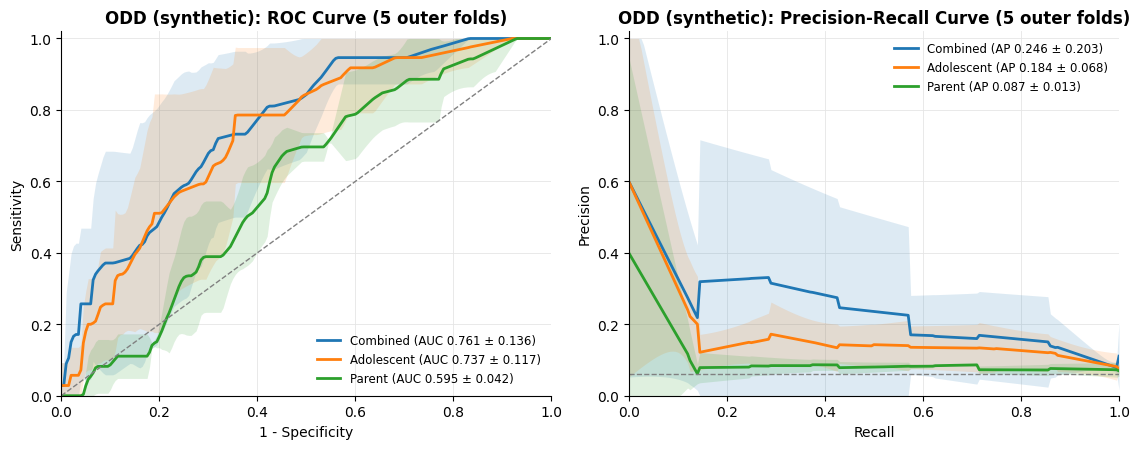

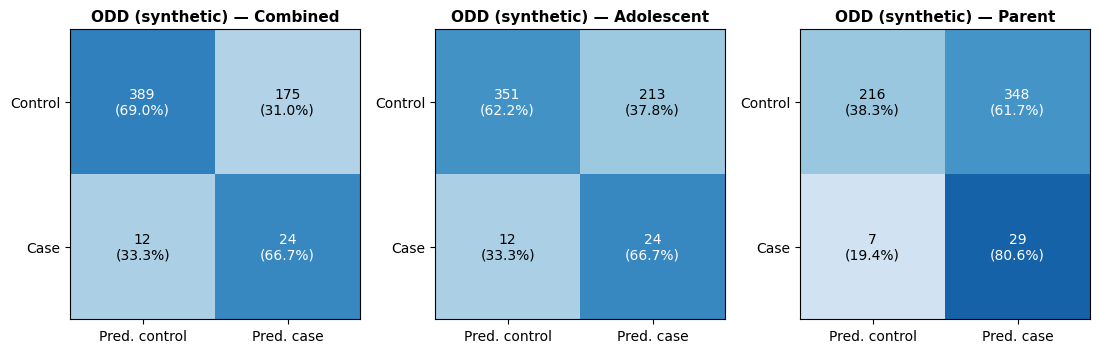

In [4]:
df = load_cohort(cfg, TARGET)
cv_res = run_locked_cv(cfg, df, TARGET, n_estimators_override=N_EST, verbose=False)
perf = cv_res["performance_summary"]
display(perf[["feature_set_label", "n", "n_cases", "auc_mean", "auc_sd", "average_precision_mean",
              "recall_mean", "specificity_mean", "f1_mean", "f1_sd"]].round(3))

fig = plots.roc_pr_ribbons(cv_res["roc_pr_curves"], perf, title_prefix=f"{TARGET.upper()} ({MODE}): ")
plt.show()
fig = plots.confusion_grid(cv_res["confusion_pooled"], title_prefix=f"{TARGET.upper()} ({MODE}) — ")
plt.show()

## 3. Post-hoc explainability on outer-test folds (TreeSHAP and Permutation ΔAUC)


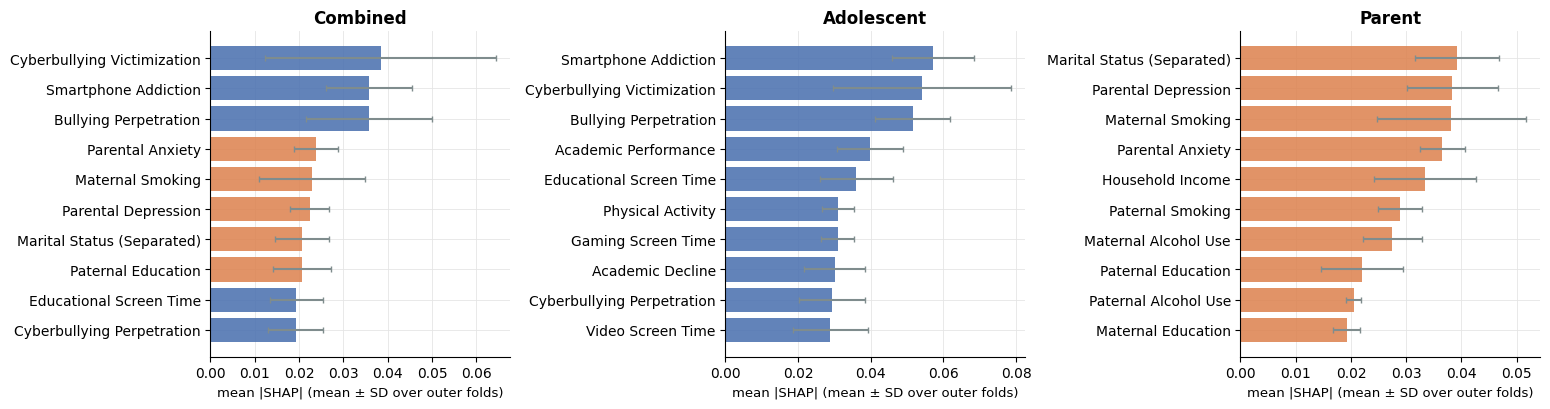

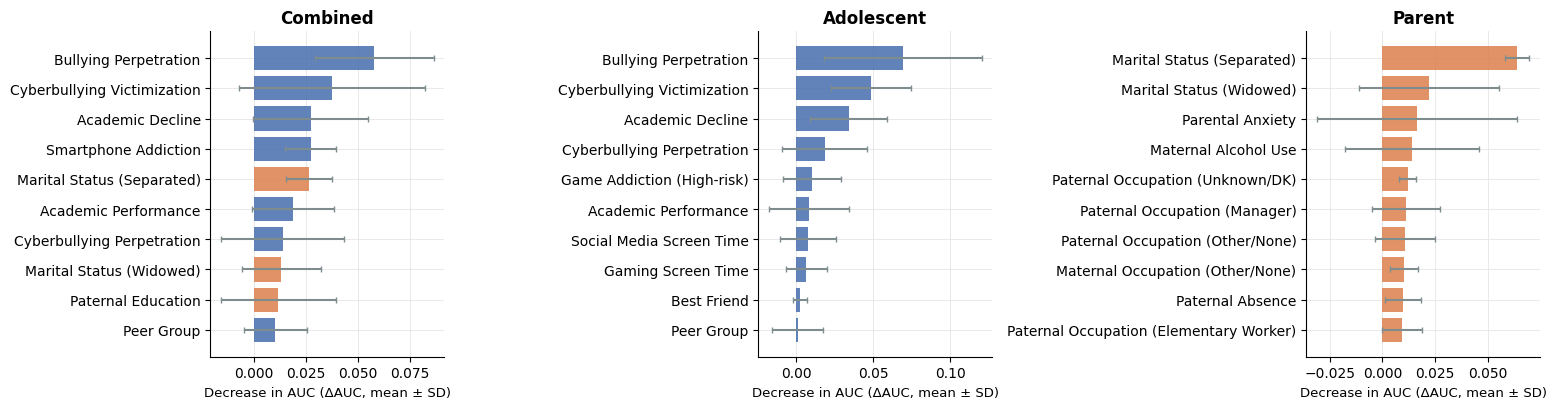

In [5]:
imp_res = run_importance(cfg, df, TARGET, n_estimators_override=N_EST, verbose=False)
fig = plots.importance_bars(imp_res["shap_summary"], value_col="mean_abs_shap", sd_col="sd_abs_shap",
                            xlabel="mean |SHAP| (mean ± SD over outer folds)", top_k=10)
plt.show()
fig = plots.importance_bars(imp_res["permutation_summary"], value_col="delta_auc_mean", sd_col="delta_auc_sd",
                            xlabel="Decrease in AUC (ΔAUC, mean ± SD)", top_k=10)
plt.show()

## 4. Covariate-adjusted logistic regression odds ratios (Benjamini–Hochberg FDR)

Adjusted models control for adolescent sex, age, parental depression (`PHQ-9 >= 9`), and
parental anxiety (`GAD-7 >= 5`), dropping a covariate only when it is itself the exposure tested.


,Level,Variable,Contrast,SHAP Rank (C/A/P),N,N_cases,Crude OR (95% CI),Adjusted OR (95% CI),p,q (FDR)
0,Adolescent-level,Cyberbullying Victimization,yes vs no,1/2/-,577,34,4.38 (2.16-8.87),4.35 (2.13-8.87),<0.001,<0.001
1,Adolescent-level,Smartphone Addiction,per 1 SD,2/1/-,577,34,1.59 (1.12-2.26),1.58 (1.11-2.25),0.012,0.057
2,Adolescent-level,Bullying Perpetration,yes vs no,3/3/-,577,34,5.74 (2.75-11.97),6.34 (2.98-13.47),<0.001,<0.001
3,Adolescent-level,Academic Performance,per step toward a lower grade,-/4/-,569,34,1.22 (0.93-1.60),1.25 (0.95-1.64),0.111,0.316
4,Adolescent-level,Educational Screen Time,>=3 h/day vs <3 h/day,9/5/-,577,34,1.82 (0.91-3.66),1.97 (0.97-3.99),0.060,0.199
5,Adolescent-level,Physical Activity,per higher activity category (1-5),-/6/-,577,34,0.92 (0.68-1.25),0.94 (0.69-1.28),0.691,0.768
6,Adolescent-level,Gaming Screen Time,>=3 h/day vs <3 h/day,-/7/-,577,34,0.76 (0.36-1.63),0.72 (0.33-1.55),0.403,0.565
7,Adolescent-level,Academic Decline,yes vs no,-/8/-,577,34,2.67 (1.28-5.59),2.86 (1.35-6.06),0.006,0.041
8,Adolescent-level,Cyberbullying Perpetration,yes vs no,10/9/-,577,34,2.34 (1.08-5.08),2.70 (1.22-5.98),0.014,0.057
9,Adolescent-level,Video Screen Time,>=3 h/day vs <3 h/day,-/10/-,577,34,0.75 (0.35-1.60),0.74 (0.34-1.58),0.432,0.565


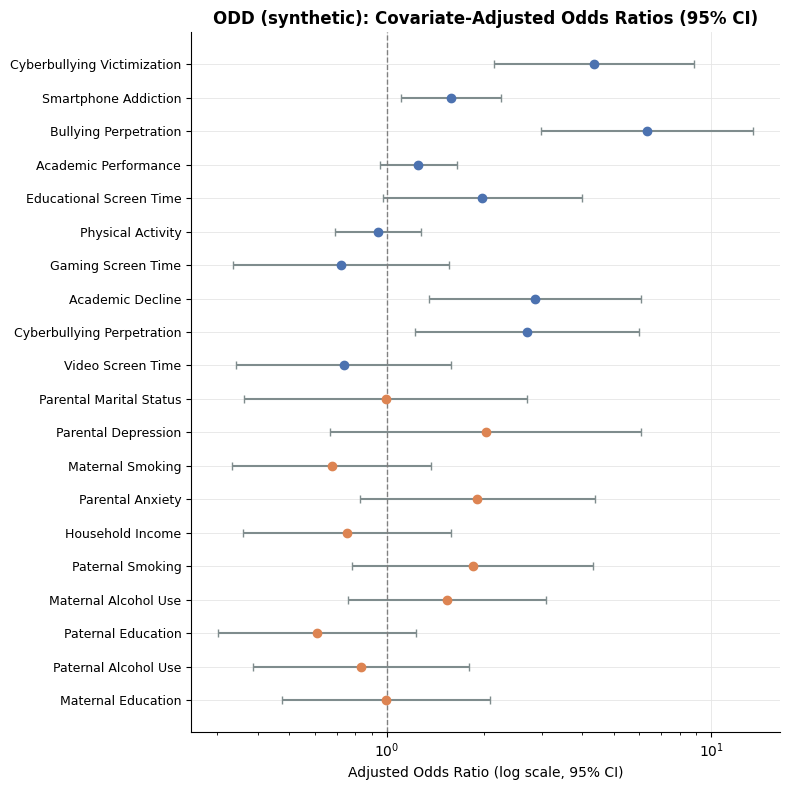

In [6]:
assoc_df, corr_df = run_association(cfg, df, TARGET)
cols = ["Level", "Variable", "Contrast", "SHAP Rank (C/A/P)", "N", "N_cases",
        "Crude OR (95% CI)", "Adjusted OR (95% CI)", "p", "q (FDR)"]
display(assoc_df[cols])
fig = plots.association_forest(assoc_df, title=f"{TARGET.upper()} ({MODE}): Covariate-Adjusted Odds Ratios (95% CI)")
plt.show()

## 5. Calibration, paired DeLong tests, and perpetration-excluded sensitivity


In [7]:
rob_res = run_robustness(cfg, df, TARGET, n_estimators_override=N_EST)
display(rob_res["calibration"].round(4))
display(rob_res["delong"].round(4))
display(rob_res["perpetration_sensitivity"].round(4))

if _tmp_ctx is not None:
    _tmp_ctx.cleanup()

,cohort,target_label,feature_set,scheme,pooled_auc,brier_score,ece_10bin,mean_pred_risk,observed_prevalence
0,odd,ODD,Combined,raw,0.7476,0.0560,0.0427,0.1027,0.06
1,odd,ODD,Combined,platt,0.7238,0.0557,0.0111,0.0618,0.06
2,odd,ODD,Combined,isotonic,0.7092,0.0587,0.0199,0.0623,0.06
3,odd,ODD,Adolescent,raw,0.7357,0.0572,0.0379,0.0976,0.06
4,odd,ODD,Adolescent,platt,0.7170,0.0552,0.0120,0.0613,0.06
5,odd,ODD,Adolescent,isotonic,0.6935,0.0574,0.0157,0.0609,0.06
6,odd,ODD,Parent,raw,0.5975,0.0626,0.0457,0.1057,0.06
7,odd,ODD,Parent,platt,0.6021,0.0561,0.0010,0.0600,0.06
8,odd,ODD,Parent,isotonic,0.6114,0.0559,0.0067,0.0605,0.06


,cohort,comparison,delta_auc,boot_ci95_low,boot_ci95_high,delong_p
0,odd,Combined vs Adolescent,0.0119,-0.0712,0.1001,0.7881
1,odd,Combined vs Parent,0.1501,0.0700,0.2332,0.0004


,cohort,feature_set,dropped_columns,auc_mean,auc_sd,f1_mean,f1_sd
0,odd,Combined,"SV3_code,CV2_code",0.6962,0.1388,0.1405,0.0479
1,odd,Adolescent,"SV3_code,CV2_code",0.6907,0.1286,0.0990,0.0712
